# Airline Satisfaction Prediction with Quantized PyTorch Network

This notebook predicts passenger satisfaction using standardized and quantized numerical and ordinal features with one hidden layer. Categorical features are one-hot encoded. Quantization is selected with stratified cross-validation using ROC-AUC, and a holdout split is used for evaluation. The final model is trained on all labelled rows to produce `submission.csv`.

## 1. Imports and configuration

In [25]:
from pathlib import Path
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, log_loss
from IPython.display import display

SEED = 42
TARGET = "satisfaction"
ID_COL = "id"
ROUND_DIGITS = 1
QUANT_COEFFICIENTS = list(range(1, 11))
N_FOLDS = 5
CV_EPOCHS = 120
FINAL_EPOCHS = 120
HIDDEN_UNITS = 20
MAX_CV_ROWS = 10000
VALID_SIZE = 0.30
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-4

KAGGLE_DATA_DIR = Path("/kaggle/input/playground-series-s6e10")
if KAGGLE_DATA_DIR.exists():
    DATA_DIR = KAGGLE_DATA_DIR
else:
    candidates = [p.parent for p in Path("/kaggle/input").rglob("train.csv")] if Path("/kaggle/input").exists() else []
    matching = [p for p in candidates if (p / "test.csv").exists()]
    DATA_DIR = matching[0] if matching else Path.cwd()

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))

print(f"Device: {DEVICE}")
print(f"Data directory: {DATA_DIR}")


Device: cpu
Data directory: d:\Code\kaggle


## 2. Load data

The identifier is kept for the submission but excluded from model inputs. The target is encoded as 0/1.

In [26]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
train_df.columns = train_df.columns.astype(str).str.strip()
test_df.columns = test_df.columns.astype(str).str.strip()

if TARGET not in train_df.columns:
    raise ValueError(f"Target column {TARGET!r} was not found in train.csv")
if ID_COL not in test_df.columns:
    raise ValueError(f"Identifier column {ID_COL!r} was not found in test.csv")

target_map = {
    "true": 1,
    "false": 0,
    "1": 1,
    "0": 0,
    "1.0": 1,
    "0.0": 0,
    "yes": 1,
    "no": 0
}
y_series = train_df[TARGET].astype(str).str.strip().str.lower().map(target_map)
if y_series.isna().any():
    raise ValueError("Unexpected values were found in the target column")
train_df[TARGET] = y_series.astype(np.int64)
y_all = train_df[TARGET].to_numpy(dtype=np.int64)

feature_cols = [c for c in train_df.columns if c not in {TARGET, ID_COL} and not c.lower().startswith("unnamed:")]
numeric_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(train_df[c])]
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

train_part, valid_part = train_test_split(
    train_df,
    test_size=VALID_SIZE,
    random_state=SEED,
    stratify=y_all
)
train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)
y_fit = train_part[TARGET].to_numpy(dtype=np.int64)
y_valid = valid_part[TARGET].to_numpy(dtype=np.int64)

print(f"Training rows: {len(train_df):,}")
print(f"Test rows: {len(test_df):,}")
print(f"Numerical and ordinal features: {len(numeric_cols)}")
print(f"Categorical features: {len(categorical_cols)}")
print(f"Fit rows: {len(train_part):,}; holdout rows: {len(valid_part):,}")
print(f"Target positive rate: {y_all.mean():.4f}")


Training rows: 699,635
Test rows: 299,844
Numerical and ordinal features: 17
Categorical features: 4
Fit rows: 489,744; holdout rows: 209,891
Target positive rate: 0.4436


## Feature aggregation and network

Rows with identical quantized input vectors are grouped before training. The target stored for each group is the fraction of positive labels, and the group count is used as the loss weight. This preserves the full binary cross-entropy contribution even when identical inputs have different target labels. The network has one hidden layer with 10 neurons.

In [27]:
def excel_round(values, digits=ROUND_DIGITS):
    values = np.asarray(values, dtype=np.float64)
    factor = 10.0 ** digits
    return np.sign(values) * np.floor(np.abs(values) * factor + 0.5 + 1e-12) / factor


def quantize_values(values, coefficient, digits=ROUND_DIGITS):
    rounded = excel_round(values, digits)
    codes = np.trunc(rounded * (10.0 ** digits) / coefficient).astype(np.int64)
    quantized = codes.astype(np.float64) * coefficient / (10.0 ** digits)
    return codes, quantized


def categorical_value(value):
    if pd.isna(value):
        return "__MISSING__"
    return str(value).strip()


def fit_preprocessing_state(frame):
    state = {"numeric": {}, "categorical": {}, "numeric_cols": list(numeric_cols), "categorical_cols": list(categorical_cols)}
    for column in numeric_cols:
        values = pd.to_numeric(frame[column], errors="coerce")
        median = float(values.median()) if values.notna().any() else 0.0
        filled = values.fillna(median).to_numpy(dtype=np.float64)
        mean = float(filled.mean())
        std = float(filled.std(ddof=1)) if len(filled) > 1 else 1.0
        if not np.isfinite(std) or std == 0:
            std = 1.0
        state["numeric"][column] = {"median": median, "mean": mean, "std": std}
    for column in categorical_cols:
        values = [categorical_value(v) for v in frame[column].to_numpy()]
        levels = sorted(set(values) | {"__MISSING__"})
        state["categorical"][column] = {"levels": levels}
    return state


def transform_features(frame, state, coefficient):
    parts = []
    for column in state["numeric_cols"]:
        params = state["numeric"][column]
        values = pd.to_numeric(frame[column], errors="coerce").fillna(params["median"]).to_numpy(dtype=np.float64)
        scaled = (values - params["mean"]) / params["std"]
        _, quantized = quantize_values(scaled, coefficient)
        parts.append(quantized.reshape(-1, 1).astype(np.float32))
    for column in state["categorical_cols"]:
        levels = state["categorical"][column]["levels"]
        values = np.asarray([categorical_value(v) for v in frame[column].to_numpy()], dtype=object)
        for level in levels[1:]:
            parts.append((values == level).astype(np.float32).reshape(-1, 1))
    if not parts:
        raise ValueError("No model features were created")
    matrix = np.concatenate(parts, axis=1).astype(np.float32)
    return matrix


def aggregate_training_rows(matrix, target):
    matrix = np.asarray(matrix, dtype=np.float32)
    target = np.asarray(target, dtype=np.int64).reshape(-1)
    unique_inputs, inverse = np.unique(matrix, axis=0, return_inverse=True)
    counts = np.bincount(inverse).astype(np.float32)
    positive_counts = np.bincount(inverse, weights=target.astype(np.float64)).astype(np.float32)
    grouped_targets = (positive_counts / counts).astype(np.float32).reshape(-1, 1)
    return unique_inputs.astype(np.float32), grouped_targets, counts


class TinyTorchNet(nn.Module):
    def __init__(self, input_dim, hidden_units=HIDDEN_UNITS):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_units),
            nn.Tanh(),
            nn.Linear(hidden_units, 1)
        )

    def forward(self, values):
        return self.network(values)


def train_model(matrix, target, epochs, seed=SEED):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    grouped_x, grouped_y, grouped_weights = aggregate_training_rows(matrix, target)
    model = TinyTorchNet(grouped_x.shape[1]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.BCEWithLogitsLoss(reduction="none")
    x_tensor = torch.as_tensor(grouped_x, dtype=torch.float32, device=DEVICE)
    y_tensor = torch.as_tensor(grouped_y, dtype=torch.float32, device=DEVICE)
    weight_tensor = torch.as_tensor(grouped_weights.reshape(-1, 1), dtype=torch.float32, device=DEVICE)
    history = []
    checkpoints = {1, 10, 25, 50, 100, epochs}
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(x_tensor)
        losses = loss_function(logits, y_tensor)
        loss = (losses * weight_tensor).sum() / weight_tensor.sum()
        loss.backward()
        optimizer.step()
        if epoch in checkpoints:
            history.append({"epoch": epoch, "weighted_bce": float(loss.detach().cpu().item())})
    return model, history, len(grouped_x)


def predict_probability(model, matrix, batch_size=65536):
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(matrix), batch_size):
            batch = torch.as_tensor(matrix[start:start + batch_size], dtype=torch.float32, device=DEVICE)
            outputs.append(torch.sigmoid(model(batch)).detach().cpu().numpy().ravel())
    return np.concatenate(outputs)


def calculate_metrics(target, probability):
    probability = np.clip(np.asarray(probability, dtype=np.float64), 1e-7, 1 - 1e-7)
    prediction = (probability >= 0.5).astype(np.int64)
    return {
        "ROC-AUC": float(roc_auc_score(target, probability)),
        "Accuracy": float(accuracy_score(target, prediction)),
        "Precision": float(precision_score(target, prediction, zero_division=0)),
        "Recall": float(recall_score(target, prediction, zero_division=0)),
        "F1": float(f1_score(target, prediction, zero_division=0)),
        "LogLoss": float(log_loss(target, probability, labels=[0, 1]))
    }


## 4. Quantization coefficient search

The coefficient is selected by the mean ROC-AUC over stratified folds. To keep the search tractable on the full competition dataset, cross-validation uses up to 10,000 rows selected from the fit partition. The holdout partition is not used during coefficient selection.

c= 1 | mean CV ROC-AUC=0.94442 ± 0.00344
c= 2 | mean CV ROC-AUC=0.94362 ± 0.00460
c= 3 | mean CV ROC-AUC=0.94472 ± 0.00413
c= 4 | mean CV ROC-AUC=0.94286 ± 0.00626
c= 5 | mean CV ROC-AUC=0.93974 ± 0.00639
c= 6 | mean CV ROC-AUC=0.94296 ± 0.00492
c= 7 | mean CV ROC-AUC=0.94568 ± 0.00506
c= 8 | mean CV ROC-AUC=0.94245 ± 0.00751
c= 9 | mean CV ROC-AUC=0.94280 ± 0.00554
c=10 | mean CV ROC-AUC=0.93530 ± 0.00651


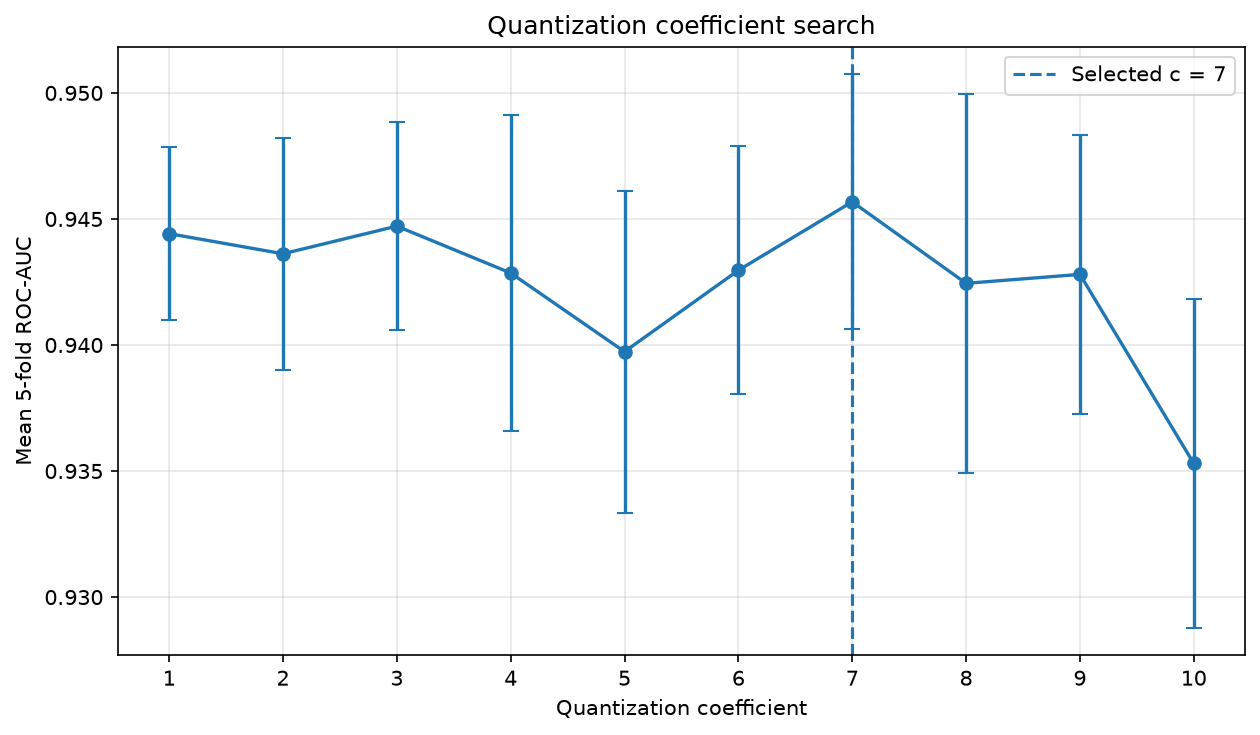

Selected coefficient: 7
Quantization step: 0.7
Mean CV ROC-AUC: 0.94568 ± 0.00506


,coefficient,quantization_step,roc_auc_mean,roc_auc_std,accuracy_mean,precision_mean,recall_mean,f1_mean,logloss_mean,selected
0,1,0.1,0.94442,0.00344,0.8996,0.90118,0.86903,0.88478,0.28424,False
1,2,0.2,0.94362,0.00460,0.8983,0.90053,0.86655,0.88319,0.28677,False
2,3,0.3,0.94472,0.00413,0.8990,0.89851,0.87083,0.88441,0.28356,False
3,4,0.4,0.94286,0.00626,0.8970,0.89916,0.86497,0.88170,0.28850,False
4,5,0.5,0.93974,0.00639,0.8903,0.89073,0.85798,0.87404,0.29762,False
5,6,0.6,0.94296,0.00492,0.8933,0.89261,0.86339,0.87775,0.29115,False
6,7,0.7,0.94568,0.00506,0.8988,0.89655,0.87263,0.88441,0.28311,True
7,8,0.8,0.94245,0.00751,0.8917,0.89078,0.86159,0.87593,0.29290,False
8,9,0.9,0.94280,0.00554,0.8929,0.88378,0.87354,0.87860,0.29419,False
9,10,1.0,0.93530,0.00651,0.8888,0.89354,0.85077,0.87159,0.30666,False


In [28]:
if len(train_part) > MAX_CV_ROWS:
    cv_frame, _ = train_test_split(
        train_part,
        train_size=MAX_CV_ROWS,
        random_state=SEED,
        stratify=train_part[TARGET]
    )
    cv_frame = cv_frame.reset_index(drop=True)
else:
    cv_frame = train_part.copy().reset_index(drop=True)

y_cv = cv_frame[TARGET].to_numpy(dtype=np.int64)
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(cv_frame, y_cv))
quantization_rows = []
search_start = time.time()

for coefficient in QUANT_COEFFICIENTS:
    fold_metrics = []
    for fold_number, (train_indices, valid_indices) in enumerate(folds, start=1):
        cv_train = cv_frame.iloc[train_indices].reset_index(drop=True)
        cv_valid = cv_frame.iloc[valid_indices].reset_index(drop=True)
        y_cv_train = cv_train[TARGET].to_numpy(dtype=np.int64)
        y_cv_valid = cv_valid[TARGET].to_numpy(dtype=np.int64)
        state = fit_preprocessing_state(cv_train)
        x_cv_train = transform_features(cv_train, state, coefficient)
        x_cv_valid = transform_features(cv_valid, state, coefficient)
        model, _, grouped_rows = train_model(
            x_cv_train,
            y_cv_train,
            CV_EPOCHS,
            seed=SEED + coefficient * 100 + fold_number
        )
        probability = predict_probability(model, x_cv_valid)
        fold_metrics.append(calculate_metrics(y_cv_valid, probability))
        del model
    auc_values = [m["ROC-AUC"] for m in fold_metrics]
    quantization_rows.append({
        "coefficient": coefficient,
        "quantization_step": coefficient / (10 ** ROUND_DIGITS),
        "roc_auc_mean": float(np.mean(auc_values)),
        "roc_auc_std": float(np.std(auc_values, ddof=1)),
        "accuracy_mean": float(np.mean([m["Accuracy"] for m in fold_metrics])),
        "precision_mean": float(np.mean([m["Precision"] for m in fold_metrics])),
        "recall_mean": float(np.mean([m["Recall"] for m in fold_metrics])),
        "f1_mean": float(np.mean([m["F1"] for m in fold_metrics])),
        "logloss_mean": float(np.mean([m["LogLoss"] for m in fold_metrics]))
    })
    print(f"c={coefficient:2d} | mean CV ROC-AUC={np.mean(auc_values):.5f} ± {np.std(auc_values, ddof=1):.5f}")

quantization_results = pd.DataFrame(quantization_rows)
best_row = quantization_results.loc[quantization_results["roc_auc_mean"].idxmax()]
best_coefficient = int(best_row["coefficient"])
quantization_results["selected"] = quantization_results["coefficient"].eq(best_coefficient)
quantization_results.to_csv(OUTPUT_DIR / "one_hidden_quantization_search_results.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 5), dpi=150)
ax.errorbar(
    quantization_results["coefficient"],
    quantization_results["roc_auc_mean"],
    yerr=quantization_results["roc_auc_std"],
    fmt="o-",
    capsize=4,
    linewidth=1.6
)
ax.axvline(best_coefficient, linestyle="--", label=f"Selected c = {best_coefficient}")
ax.set_xlabel("Quantization coefficient")
ax.set_ylabel(f"Mean {N_FOLDS}-fold ROC-AUC")
ax.set_title("Quantization coefficient search")
ax.set_xticks(QUANT_COEFFICIENTS)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "one_hidden_quantization_search.png", bbox_inches="tight")
plt.show()

print(f"Selected coefficient: {best_coefficient}")
print(f"Quantization step: {best_coefficient / (10 ** ROUND_DIGITS):.1f}")
print(f"Mean CV ROC-AUC: {best_row['roc_auc_mean']:.5f} ± {best_row['roc_auc_std']:.5f}")
display(quantization_results.round(5))


## 5. Holdout evaluation

The selected coefficient is evaluated on the reserved holdout partition. The metrics below are calculated at a probability threshold of 0.5, except ROC-AUC and LogLoss, which use predicted probabilities.

Rows before aggregation: 489,744
Rows after aggregation: 351,745


,ROC-AUC,Accuracy,Precision,Recall,F1,LogLoss
0,0.9442,0.8977,0.8997,0.8661,0.8825,0.2848


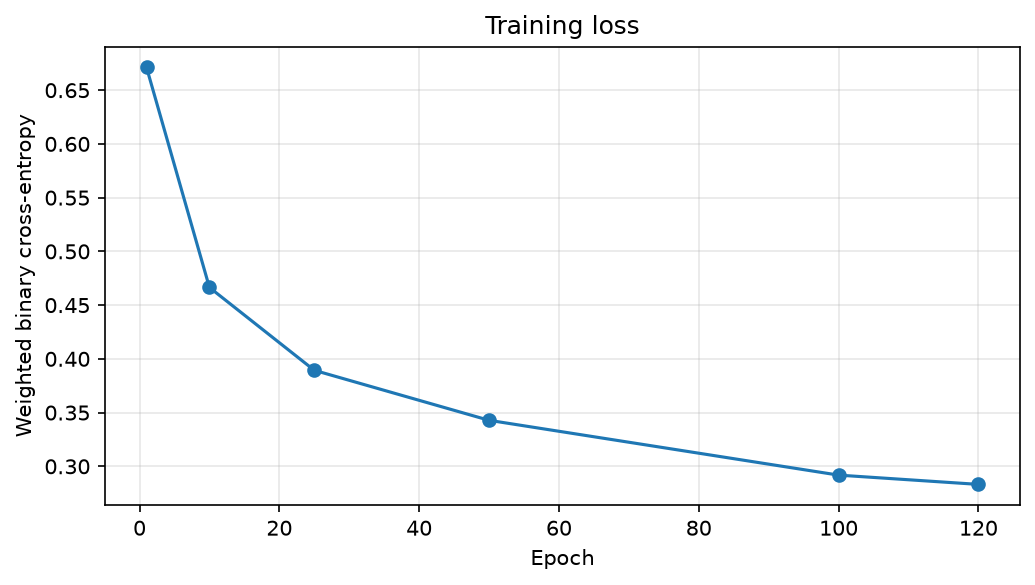

In [29]:
state_fit = fit_preprocessing_state(train_part)
x_fit = transform_features(train_part, state_fit, best_coefficient)
x_valid = transform_features(valid_part, state_fit, best_coefficient)
validation_model, training_history, grouped_fit_rows = train_model(
    x_fit,
    y_fit,
    FINAL_EPOCHS,
    seed=SEED + 777
)
valid_probability = predict_probability(validation_model, x_valid)
validation_metrics = calculate_metrics(y_valid, valid_probability)
validation_table = pd.DataFrame([validation_metrics])
validation_table.to_csv(OUTPUT_DIR / "one_hidden_validation_metrics.csv", index=False)
pd.DataFrame(training_history).to_csv(OUTPUT_DIR / "one_hidden_training_history.csv", index=False)

print(f"Rows before aggregation: {len(x_fit):,}")
print(f"Rows after aggregation: {grouped_fit_rows:,}")
display(validation_table.round(4))

history_frame = pd.DataFrame(training_history)
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.plot(history_frame["epoch"], history_frame["weighted_bce"], marker="o")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted binary cross-entropy")
ax.set_title("Training loss")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "one_hidden_training_curve.png", bbox_inches="tight")
plt.show()


## 6. Train on all labelled rows and create submission

After evaluation, preprocessing is fitted on all labelled rows and the final model is trained on the complete training dataset. Predictions are exported as probabilities in the required submission format.

In [30]:
state_full = fit_preprocessing_state(train_df)
x_full = transform_features(train_df, state_full, best_coefficient)
x_test = transform_features(test_df, state_full, best_coefficient)
final_model, final_history, grouped_full_rows = train_model(
    x_full,
    y_all,
    FINAL_EPOCHS,
    seed=SEED + 2026
)
test_probability = predict_probability(final_model, x_test)

submission = pd.DataFrame({
    ID_COL: test_df[ID_COL].to_numpy(),
    TARGET: test_probability
})

if SAMPLE_SUBMISSION_PATH.exists():
    sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)
    if len(sample_submission) != len(submission):
        print(f"Submission was not saved: test has {len(submission):,} rows, but sample_submission has {len(sample_submission):,} rows.")
    else:
        if set(sample_submission.columns) == set(submission.columns):
            submission = submission[sample_submission.columns]
        submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
        print(f"Saved: {OUTPUT_DIR / 'submission.csv'}")
else:
    submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
    print(f"Saved: {OUTPUT_DIR / 'submission.csv'}")

print(f"Selected quantization coefficient: {best_coefficient}")
print(f"Full training rows: {len(x_full):,}")
print(f"Full training rows after aggregation: {grouped_full_rows:,}")
print(f"Submission shape: {submission.shape}")
display(submission.head())


Saved: d:\Code\kaggle\submission.csv
Selected quantization coefficient: 7
Full training rows: 699,635
Full training rows after aggregation: 476,793
Submission shape: (299844, 2)


,id,satisfaction
0,699635,0.194245
1,699636,0.866443
2,699637,0.682660
3,699638,0.040601
4,699639,0.030460


## 7. Saved artifacts

The notebook saves `submission.csv`, `quantization_search_results.csv`, `quantization_search.png`, `validation_metrics.csv`, `training_history.csv`, and `training_curve.png` to the working directory. The final submission contains the `id` column and predicted `satisfaction` probabilities.